# NLP Take-Home Assessment — Track A: Spam Filter

**Task:** classify SMS messages as legitimate (**ham**) or unwanted (**spam**).
**Dataset:** UCI SMS Spam Collection (5,574 labelled SMS messages).
**Pipeline:** tokenization → TF-IDF → Logistic Regression → error analysis.

| Part | Content |
|---|---|
| 1 | Data loading & EDA, three tokenization strategies, comparison & reflection |
| 2 | TF-IDF vectorization, hyperparameter selection & justification |
| 3 | Stratified split, model training, accuracy / precision / recall / F1, confusion matrix |
| 4 | Error analysis of false positives and false negatives |

The notebook is fully reproducible: every random operation uses `RANDOM_STATE = 42`, and the dataset is downloaded directly from the UCI repository (no manual upload needed on Colab).

---
## 0. Environment Setup

### Explanation

* `pandas` / `numpy`: tabular data handling.
* `re`: regular expressions (Strategy 1 tokenizer, as in the regex lab).
* `nltk`: library tokenizers (`word_tokenize`, `TweetTokenizer`).
* `sklearn`: `TfidfVectorizer`, `LogisticRegression`, `MultinomialNB`, splitting, cross-validation and metrics.
* `matplotlib` / `seaborn`: plots and the confusion-matrix heatmap.

In [1]:
import io
import re
import zipfile
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.tokenize import word_tokenize, TweetTokenizer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)

# Tokenizer models required by word_tokenize (punkt_tab is needed on newer NLTK versions)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

RANDOM_STATE = 42
pd.set_option('display.max_colwidth', 120)
sns.set_theme(style='whitegrid')

print("Environment configured successfully!")

Environment configured successfully!


---
# Part 1: Data Preprocessing & Tokenization

## 1.1 Dataset Loading & EDA

### Explanation

The UCI archive is a zip containing a tab-separated file `SMSSpamCollection` with two columns: the label (`ham`/`spam`) and the raw message. We pass `quoting=3` (`csv.QUOTE_NONE`) because some messages contain unbalanced `"` characters that would otherwise break parsing.

In [2]:
DATA_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

raw_zip = urllib.request.urlopen(DATA_URL).read()
with zipfile.ZipFile(io.BytesIO(raw_zip)) as z:
    df = pd.read_csv(z.open('SMSSpamCollection'), sep='\t', header=None,
                     names=['label', 'text'], quoting=3)

print(f"Total rows: {len(df)}")
df.head()

Total rows: 5574


,label,text
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


In [3]:
# Target class distribution
dist = pd.DataFrame({'count': df['label'].value_counts(),
                     'percent': (df['label'].value_counts(normalize=True) * 100).round(2)})
print(dist, "\n")

# Message length statistics per class
df['n_chars'] = df['text'].str.len()
df['n_words'] = df['text'].str.split().str.len()
df.groupby('label')[['n_chars', 'n_words']].describe().round(1)

       count  percent
label                
ham     4827     86.6
spam     747     13.4 



n_chars                                                n_words        \
        count   mean   std   min    25%    50%    75%    max   count  mean   
label                                                                        
ham    4827.0   71.5  58.3   2.0   33.0   52.0   93.0  910.0  4827.0  14.3   
spam    747.0  138.7  28.9  13.0  133.0  149.0  157.0  223.0   747.0  23.9   

                                           
        std  min   25%   50%   75%    max  
label                                      
ham    11.5  1.0   7.0  11.0  19.0  171.0  
spam    5.8  2.0  22.0  25.0  28.0   35.0

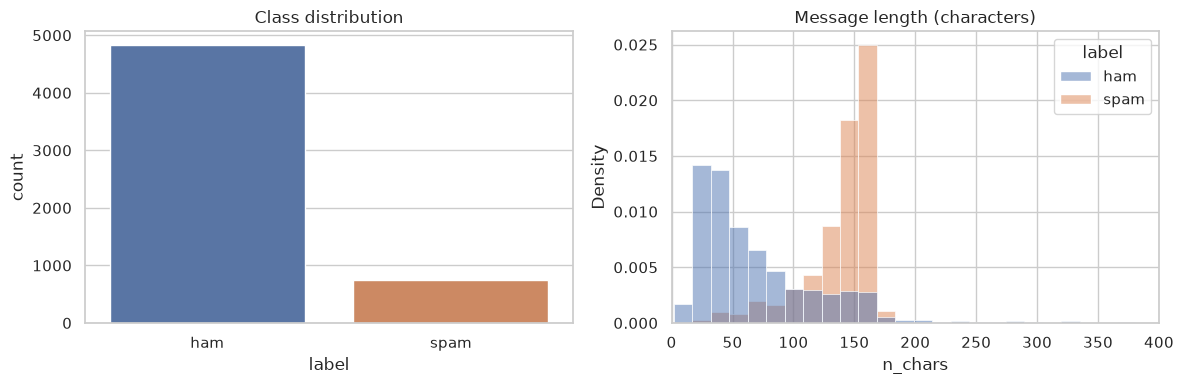

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df, x='label', hue='label', ax=axes[0], palette={'ham': '#4C72B0', 'spam': '#DD8452'})
axes[0].set_title('Class distribution')

sns.histplot(data=df, x='n_chars', hue='label', bins=60, ax=axes[1], stat='density', common_norm=False,
             palette={'ham': '#4C72B0', 'spam': '#DD8452'})
axes[1].set_xlim(0, 400)
axes[1].set_title('Message length (characters)')

plt.tight_layout()
plt.show()

In [5]:
# Representative samples from each class
for label in ['ham', 'spam']:
    print(f"===== {label.upper()} samples =====")
    for text in df[df['label'] == label]['text'].sample(4, random_state=RANDOM_STATE):
        print(" •", text)
    print()

===== HAM samples =====
 • Dear,Me at cherthala.in case u r coming cochin pls call bfore u start.i shall also reach accordingly.or tell me which day u r coming.tmorow i am engaged ans its holiday.
 • Ok. I only ask abt e movie. U wan ktv oso?
 • Convey my regards to him
 • Hi Jon, Pete here, Ive bin 2 Spain recently & hav sum dinero left, Bill said u or ur rents mayb interested in it, I hav 12,000pes, so around £48, tb, James.

===== SPAM samples =====
 • Summers finally here! Fancy a chat or flirt with sexy singles in yr area? To get MATCHED up just reply SUMMER now. Free 2 Join. OptOut txt STOP Help08714742804
 • This is the 2nd time we have tried 2 contact u. U have won the 750 Pound prize. 2 claim is easy, call 08718726970 NOW! Only 10p per min. BT-national-rate 
 • Get ur 1st RINGTONE FREE NOW! Reply to this msg with TONE. Gr8 TOP 20 tones to your phone every week just £1.50 per wk 2 opt out send STOP 08452810071 16
 • Ur cash-balance is currently 500 pounds - to maximize ur cash

### Data quality: duplicates

SMS corpora contain many repeated messages (chain messages, the same spam campaign sent to several numbers). If an identical message lands in both the training and the test set, the model is effectively tested on data it has already memorised, which inflates the scores. We therefore drop exact duplicates **before** splitting.

In [6]:
n_dup = df['text'].duplicated().sum()
print(f"Exact duplicate messages: {n_dup}")
print("Duplicates by class:\n", df[df['text'].duplicated()]['label'].value_counts(), "\n")

df = df.drop_duplicates(subset='text').reset_index(drop=True)
df['y'] = (df['label'] == 'spam').astype(int)   # 1 = spam, 0 = ham

print(f"Rows after de-duplication: {len(df)}")
print(df['label'].value_counts(normalize=True).mul(100).round(2))

Exact duplicate messages: 403
Duplicates by class:
 label
ham     309
spam     94
Name: count, dtype: int64 

Rows after de-duplication: 5171
label
ham     87.37
spam    12.63
Name: proportion, dtype: float64


**EDA observations**

* The dataset is **imbalanced**: roughly 87% ham vs 13% spam. A model that always predicts "ham" would already reach ~87% accuracy, so accuracy alone is not a meaningful metric here; we focus on spam **precision / recall / F1**.
* Spam messages are much **longer** (they cluster around 130–160 characters, close to the 160-character SMS limit), while ham is usually short and conversational.
* Spam is full of **currency symbols (£), long phone numbers, short codes, URLs, CAPITALS and "!"**. Ham contains slang (`u`, `ur`, `lor`), emoticons and the artefact `&lt;#&gt;` (a placeholder the dataset authors used to anonymise numbers). These observations directly influence which tokenizer we should prefer.

## 1.2 Tokenization Strategies

### Explanation

We implement three tokenizers. All of them lowercase the text so that `FREE` and `free` map to the same token.

| # | Strategy | Idea |
|---|---|---|
| 1 | **Regex** `re.findall(r'\w+', text)` | Keep only runs of word characters (letters, digits, `_`). Everything else is a separator and is discarded. |
| 2 | **NLTK `word_tokenize`** | Penn Treebank rules: splits punctuation into separate tokens and splits contractions (`don't` → `do` + `n't`). Designed for well-formed English prose. |
| 3 | **NLTK `TweetTokenizer`** | Rules designed for social-media / short informal text: keeps emoticons (`:-)`), URLs, `@handles`, `#hashtags` and contractions intact; `reduce_len=True` shortens elongated words (`soooooo` → `sooo`). |

In [7]:
def regex_tokenize(text):
    # Strategy 1: word-character runs only
    return re.findall(r'\w+', text.lower())


def nltk_tokenize(text):
    # Strategy 2: Penn Treebank-style tokenization
    return word_tokenize(text.lower())


_tweet_tokenizer = TweetTokenizer(preserve_case=False, reduce_len=True)

def tweet_tokenize(text):
    # Strategy 3: social-media aware tokenization
    return _tweet_tokenizer.tokenize(text)


TOKENIZERS = {
    'regex': regex_tokenize,
    'nltk_word': nltk_tokenize,
    'tweet': tweet_tokenize,
}

### Behaviour on hand-picked edge cases

Before comparing the tokenizers on the whole corpus, we look at how each one treats punctuation, digits, contractions, currency, URLs and emoticons. The probe sentences use the same patterns as real messages in this dataset.

In [8]:
probes = [
    "WINNER!! You've won £1000 cash! Call 09061701461 now",
    "Visit www.prizes.co.uk or http://bit.ly/x2 to claim",
    "I don't think he's coming... u ok? :-) ;)",
    "Txt STOP to 87121. £1.50/msg 18+ only",
    "Sooooo happy, see u at 5:30pm &lt;#&gt;",
]

for p in probes:
    print(f"TEXT: {p}")
    for name, tok in TOKENIZERS.items():
        print(f"  {name:<10} {tok(p)}")
    print()

TEXT: WINNER!! You've won £1000 cash! Call 09061701461 now
  regex      ['winner', 'you', 've', 'won', '1000', 'cash', 'call', '09061701461', 'now']
  nltk_word  ['winner', '!', '!', 'you', "'ve", 'won', '£1000', 'cash', '!', 'call', '09061701461', 'now']
  tweet      ['winner', '!', '!', "you've", 'won', '£', '1000', 'cash', '!', 'call', '09061701461', 'now']

TEXT: Visit www.prizes.co.uk or http://bit.ly/x2 to claim
  regex      ['visit', 'www', 'prizes', 'co', 'uk', 'or', 'http', 'bit', 'ly', 'x2', 'to', 'claim']
  nltk_word  ['visit', 'www.prizes.co.uk', 'or', 'http', ':', '//bit.ly/x2', 'to', 'claim']
  tweet      ['visit', 'www.prizes.co.uk', 'or', 'http://bit.ly/x2', 'to', 'claim']

TEXT: I don't think he's coming... u ok? :-) ;)
  regex      ['i', 'don', 't', 'think', 'he', 's', 'coming', 'u', 'ok']
  nltk_word  ['i', 'do', "n't", 'think', 'he', "'s", 'coming', '...', 'u', 'ok', '?', ':', '-', ')', ';', ')']
  tweet      ['i', "don't", 'think', "he's", 'coming', '...', 'u', 'ok

## 1.3 Comparative Analysis

### Explanation

We tokenize the whole corpus with each strategy and measure:

* **Vocabulary size**: number of distinct tokens.
* **Tokens per message**: average sequence length.
* **Special-token handling**: how many vocabulary entries are pure numbers, pure punctuation, contain `£`, look like URLs, or are emoticons.

In [9]:
URL_RE      = re.compile(r'^(https?://|www\.)|\.(com|co\.uk|net|org|biz)\b')
EMOTICON_RE = re.compile(r'^[:;=][\-o\*\']?[\)\]\(\[dDpP/\\|]+$|^<3$')
NUMBER_RE   = re.compile(r'^\d+([.,:]\d+)*$')
PUNCT_RE    = re.compile(r'^[^\w\s]+$')

tokenized = {name: df['text'].apply(tok) for name, tok in TOKENIZERS.items()}

rows = []
for name, toks in tokenized.items():
    counts = Counter(t for doc in toks for t in doc)
    vocab = set(counts)
    rows.append({
        'tokenizer': name,
        'vocab_size': len(vocab),
        'avg_tokens_per_msg': round(toks.str.len().mean(), 1),
        'number_tokens': sum(bool(NUMBER_RE.match(t)) for t in vocab),
        'punctuation_tokens': sum(bool(PUNCT_RE.match(t)) for t in vocab),
        'tokens_with_£': sum('£' in t for t in vocab),
        'url_tokens': sum(bool(URL_RE.search(t)) for t in vocab),
        'emoticon_tokens': sum(bool(EMOTICON_RE.match(t)) for t in vocab),
        "contraction_n't_split": "n't" in vocab,
    })

comparison = pd.DataFrame(rows).set_index('tokenizer')
comparison

,vocab_size,avg_tokens_per_msg,number_tokens,punctuation_tokens,tokens_with_£,url_tokens,emoticon_tokens,contraction_n't_split
tokenizer,,,,,,,,
regex,8753,16.0,578,0,0,0,0,False
nltk_word,9424,18.6,489,54,79,96,2,True
tweet,9216,18.1,610,60,1,99,17,False


### Are the discarded symbols actually informative?

The regex tokenizer throws away every non-word character. To check whether that loses useful signal, we take the tokens produced by the `TweetTokenizer` that contain **no word characters at all** (pure punctuation / symbols / emoticons) and compare how often they appear in spam vs ham messages.

In [10]:
def doc_rate(token, label):
    # Fraction of messages of the given class that contain the token
    mask = df['label'] == label
    return tokenized['tweet'][mask].apply(lambda d: token in d).mean()

symbol_counts = Counter(t for doc in tokenized['tweet'] for t in set(doc) if PUNCT_RE.match(t))
symbol_table = pd.DataFrame(
    [{'token': t, 'n_messages': n,
      'pct_of_spam': round(100 * doc_rate(t, 'spam'), 1),
      'pct_of_ham': round(100 * doc_rate(t, 'ham'), 1)}
     for t, n in symbol_counts.most_common(15)]
)
symbol_table['spam/ham ratio'] = (symbol_table['pct_of_spam'] / symbol_table['pct_of_ham'].replace(0, np.nan)).round(1)
symbol_table

,token,n_messages,pct_of_spam,pct_of_ham,spam/ham ratio
0,.,2471,70.1,44.6,1.6
1,",",1180,29.6,21.8,1.4
2,?,1172,18.2,23.3,0.8
3,!,839,47.3,11.7,4.0
4,...,722,1.2,15.8,0.1
5,..,354,1.2,7.7,0.2
6,£,218,32.6,0.1,326.0
7,&,205,20.4,1.6,12.7
8,:),197,0.0,4.4,0.0
9,<#>,197,0.0,4.4,0.0


In [11]:
# Which frequent spam tokens does each tokenizer produce? (top 25 by document frequency in spam)
spam_mask = df['label'] == 'spam'
top_spam = {
    name: [t for t, _ in Counter(t for doc in toks[spam_mask] for t in set(doc)).most_common(25)]
    for name, toks in tokenized.items()
}
pd.DataFrame(top_spam)

,regex,nltk_word,tweet
0,to,.,.
1,call,to,to
2,a,!,!
3,you,call,call
4,your,a,a
5,for,you,you
6,now,your,£
7,or,",",your
8,free,for,","
9,the,now,/


### Reflection: which tokenizer suits spam detection?

**The `TweetTokenizer` is the best fit for this task.** SMS spam is recognised less by its grammar and more by its *surface form*: currency symbols, prize amounts, premium-rate phone numbers, short codes ("txt STOP to 87121"), URLs and bursts of `!`. The regex tokenizer (`\w+`) is the simplest and gives the smallest vocabulary (8,753), but it silently deletes `£`, `!`, `?`, emoticons and URL structure: `www.prizes.co.uk` becomes four unrelated tokens, and `don't` becomes the meaningless pair `don` + `t`. The symbol table shows that these symbols are not noise. `£` appears in **32.6% of spam vs 0.1% of ham**, `!` in 47% vs 12%, and `/` in 26% vs 0.5%, while `...`, `:)` and the anonymisation placeholder `<#>` are almost exclusively ham. Throwing them away removes exactly the cues a human uses to spot spam.

`word_tokenize` keeps punctuation, but it was designed for edited English prose (the Penn Treebank). It splits contractions (`do` + `n't`), breaks emoticons and `http://` URLs into fragments (`:-)` → `:`, `-`, `)`), and glues currency to amounts (`£1000`, `£1.50/msg`), which creates **79 distinct, rare `£…` tokens** instead of one strong feature. It also produces the largest vocabulary (9,424). The `TweetTokenizer` was built for short, informal, noisy text, which is exactly what SMS is. It keeps emoticons (17 distinct ones in the vocabulary), URLs and contractions as single tokens, separates `£` into **one** feature shared by every price, decodes the HTML entities in the data (`&lt;#&gt;` → `<#>`), and shortens elongated words (`sooooo` → `sooo`). Its weakness, shared by all three tokenizers, is numbers: every phone number and short code becomes its own rare token (610 numeric tokens). That is handled in Part 2 by `min_df` and discussed again in Part 4. The cross-validation in Part 2 confirms the choice quantitatively: the tweet tokenizer gives the best F1, and `word_tokenize` gives the worst.

---
# Part 2: Feature Extraction (TF-IDF)

### Explanation

**TF-IDF** weights each token in a document by

$$\text{tfidf}(t, d) = \text{tf}(t, d) \times \text{idf}(t), \qquad \text{idf}(t) = \ln\frac{1 + N}{1 + \text{df}(t)} + 1$$

so a token that is frequent in this message but rare across the corpus (e.g. `prize`) gets a high weight, while a token that appears everywhere (e.g. `the`) gets a low one. scikit-learn then L2-normalises every row, so long and short messages are comparable.

## 2.1 Train / Test split (Part 3.1, done first)

The split is required in Part 3, but we perform it **now**. All vectorizer and model hyperparameters must be chosen using the **training set only**: tuning them on the test set would leak information and give an optimistic final score. The test set is used exactly once, in Part 3.

We use an **80/20 stratified split** so that both sets keep the ~87/13 ham/spam ratio.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    df['text'], df['y'], test_size=0.20, stratify=df['y'], random_state=RANDOM_STATE)

split_summary = pd.DataFrame({
    'rows': [len(y_train), len(y_test)],
    'spam_count': [y_train.sum(), y_test.sum()],
    'spam_%': [round(100 * y_train.mean(), 2), round(100 * y_test.mean(), 2)],
}, index=['train', 'test'])
split_summary

,rows,spam_count,spam_%
train,4136,522,12.62
test,1035,131,12.66


## 2.2 Hyperparameter Selection

### Explanation

We evaluate each candidate configuration with **5-fold stratified cross-validation on the training set**. Each configuration is a pipeline `TfidfVectorizer → LogisticRegression`, and the score is the **F1 of the spam class** (accuracy is misleading on imbalanced data). We also record the resulting **number of features**, to measure the dimensionality trade-off.

Parameters explored:

* `tokenizer`: the three strategies from Part 1.
* `stop_words`: `None` vs scikit-learn's built-in English list.
* `ngram_range`: unigrams `(1,1)`, uni+bigrams `(1,2)`, up to trigrams `(1,3)`.
* `min_df`: minimum number of training documents a token must appear in.

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make_vectorizer(tokenizer=tweet_tokenize, stop_words=None, ngram_range=(1, 1), min_df=2, max_df=1.0):
    # lowercase=False / token_pattern=None: our tokenizers already lowercase and split the text
    return TfidfVectorizer(tokenizer=tokenizer, lowercase=False, token_pattern=None,
                           stop_words=stop_words, ngram_range=ngram_range,
                           min_df=min_df, max_df=max_df, sublinear_tf=True)

def evaluate_config(**vec_params):
    pipe = make_pipeline(make_vectorizer(**vec_params),
                         LogisticRegression(max_iter=1000, class_weight='balanced'))
    scores = cross_validate(pipe, X_train, y_train, cv=cv,
                            scoring=['f1', 'precision', 'recall'])
    n_features = len(make_vectorizer(**vec_params).fit(X_train).vocabulary_)
    return {'n_features': n_features,
            'cv_f1': scores['test_f1'].mean().round(4),
            'cv_precision': scores['test_precision'].mean().round(4),
            'cv_recall': scores['test_recall'].mean().round(4)}

### Experiment A: tokenizer × stop words × n-gram range (with `min_df=2`)

In [14]:
import warnings
# sklearn warns that its stop-word list was built with its own tokenizer; harmless here
warnings.filterwarnings('ignore', message='Your stop_words may be inconsistent')

results_a = []
for tok_name, tok in TOKENIZERS.items():
    for sw in [None, 'english']:
        for ngram in [(1, 1), (1, 2), (1, 3)]:
            res = evaluate_config(tokenizer=tok, stop_words=sw, ngram_range=ngram, min_df=2)
            results_a.append({'tokenizer': tok_name, 'stop_words': sw or 'kept',
                              'ngram_range': str(ngram), **res})

results_a = pd.DataFrame(results_a).sort_values('cv_f1', ascending=False).reset_index(drop=True)
results_a

,tokenizer,stop_words,ngram_range,n_features,cv_f1,cv_precision,cv_recall
0,tweet,kept,"(1, 3)",18342,0.9527,0.9593,0.9463
1,tweet,kept,"(1, 2)",12594,0.9526,0.9610,0.9444
2,regex,kept,"(1, 2)",11079,0.9489,0.9518,0.9463
3,regex,kept,"(1, 3)",15871,0.9453,0.9448,0.9463
4,nltk_word,kept,"(1, 3)",18274,0.9379,0.9472,0.9291
5,tweet,kept,"(1, 1)",3426,0.9363,0.9287,0.9444
6,regex,kept,"(1, 1)",3347,0.9338,0.9202,0.9482
7,nltk_word,kept,"(1, 2)",12332,0.9334,0.9382,0.9291
8,regex,english,"(1, 2)",6386,0.9294,0.9260,0.9329
9,regex,english,"(1, 3)",8100,0.9276,0.9225,0.9329


In [15]:
# Average effect of each choice across the other settings
for col in ['tokenizer', 'stop_words', 'ngram_range']:
    print(results_a.groupby(col)[['n_features', 'cv_f1']].mean().round(4), "\n")

           n_features   cv_f1
tokenizer                    
nltk_word   9269.3333  0.9164
regex       7981.5000  0.9348
tweet       9417.0000  0.9350 

            n_features   cv_f1
stop_words                    
english      6819.7778  0.9176
kept        10958.7778  0.9399 

             n_features   cv_f1
ngram_range                    
(1, 1)        3259.5000  0.9214
(1, 2)        9762.8333  0.9325
(1, 3)       13645.5000  0.9324 



### Experiment B: vocabulary constraint (`min_df`, `max_df`)

Using the tweet tokenizer, no stop-word removal and uni+bigrams `(1,2)` (chosen from Experiment A, as explained below).

In [16]:
# Chosen from Experiment A (see the justification below): uni+bigrams
best_ngram = (1, 2)

results_b = []
for min_df in [1, 2, 3, 5, 10]:
    for max_df in [1.0, 0.5]:
        res = evaluate_config(tokenizer=tweet_tokenize, ngram_range=best_ngram, min_df=min_df, max_df=max_df)
        results_b.append({'min_df': min_df, 'max_df': max_df, **res})

results_b = pd.DataFrame(results_b)
results_b

,min_df,max_df,n_features,cv_f1,cv_precision,cv_recall
0,1,1.0,47167,0.9491,0.9500,0.9482
1,1,0.5,47167,0.9491,0.9500,0.9482
2,2,1.0,12594,0.9526,0.9610,0.9444
3,2,0.5,12594,0.9526,0.9610,0.9444
4,3,1.0,6803,0.9494,0.9610,0.9386
5,3,0.5,6803,0.9494,0.9610,0.9386
6,5,1.0,3593,0.9441,0.9481,0.9405
7,5,0.5,3593,0.9441,0.9481,0.9405
8,10,1.0,1581,0.9388,0.9377,0.9405
9,10,0.5,1581,0.9388,0.9377,0.9405


### Justification of the chosen parameters

**Tokenizer.** With the best settings for each, the cross-validated spam F1 is **tweet 0.953 > regex 0.949 > nltk_word 0.933**. That matches the qualitative analysis in Part 1: keeping symbols helps, and fragmenting them (`word_tokenize`) hurts.

**`min_df` / `max_df` (vocabulary constraint).** With `min_df=1`, every typo, phone number and one-off slang spelling becomes a feature: **47,167** features with bigrams. Such features occur in a single training message, so the model can only memorise them, not generalise from them. Requiring a token to appear in at least 2 documents cuts the vocabulary to **12,594 (−73%)**, and F1 actually rises slightly (0.949 → 0.953), giving a smaller, faster and more robust model. Higher thresholds (5, 10) start discarding genuinely useful rare spam words, and F1 drops (0.944, 0.939). `max_df=0.5` has **no effect at all**: in short SMS texts, no token appears in more than half the messages, not even `i` or `.`. We use `min_df` instead of `max_features` because a document-frequency threshold has a clear meaning ("seen in more than one message"), while a `max_features` cut-off is arbitrary.

**`stop_words` (kept).** For spam detection, removing stop words **hurts**, unlike in topic classification. On average across all settings, CV F1 falls from **0.940 to 0.918**, and it is lower for every tokenizer and n-gram combination. Spam is written in a distinctive second-person, imperative register ("**you** have won", "call **now**", "**your** mobile", "reply **to** claim", "**for** free"), and the English stop-word list removes `you`, `your`, `to`, `for`, `from`, `call` and `please`. Ham is full of first-person pronouns (`i`, `me`, `my`), which are themselves strong ham indicators. Part 3 shows that several of the strongest learned features are stop words. (For sentiment analysis, stop-word removal would be even more harmful, because the list contains negations like `not` and `no`.)

**`ngram_range = (1, 2)`.** Bigrams capture short phrases that unigrams cannot represent ("you have", "call now", "txt stop", "send free"). For the tweet tokenizer, going from unigrams to uni+bigrams raises CV F1 from **0.936 to 0.953**, but the feature space grows **3.7×** (3,426 → 12,594). Adding trigrams grows it a further **46%** (to 18,342 features) for an F1 change of +0.0001, which is noise. Most trigrams appear in only a couple of messages, so they mostly add sparse dimensions without new information. We therefore keep **(1, 2)**, the best trade-off between accuracy and dimensionality.

**`sublinear_tf=True`.** This replaces the raw term count with `1 + log(tf)`, so a message that repeats `FREE FREE FREE` does not dominate purely through repetition.

## 2.3 Final Vectorizer

We fit the vectorizer on the **training set only** (`fit_transform`) and reuse the same fitted vocabulary to `transform` the test set, so that the test data cannot influence the vocabulary or the IDF weights.

In [17]:
vectorizer = make_vectorizer(tokenizer=tweet_tokenize, stop_words=None, ngram_range=best_ngram, min_df=2)

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

density = X_train_vec.nnz / (X_train_vec.shape[0] * X_train_vec.shape[1])
print(f"Train matrix: {X_train_vec.shape}   Test matrix: {X_test_vec.shape}")
print(f"Non-zero entries: {X_train_vec.nnz:,}  ->  density = {100 * density:.3f}% (very sparse)")

feature_names = vectorizer.get_feature_names_out()
idf = pd.Series(vectorizer.idf_, index=feature_names)
print("\nLowest IDF (most common) features: ", list(idf.nsmallest(10).index))

Train matrix: (4136, 12594)   Test matrix: (1035, 12594)
Non-zero entries: 101,468  ->  density = 0.195% (very sparse)

Lowest IDF (most common) features:  ['.', 'i', 'to', 'you', '?', ',', 'a', 'the', '!', 'and']


---
# Part 3: Model Training & Evaluation

## 3.1 Data Splitting

Already done in **Section 2.1**: an 80/20 split stratified on the label (`stratify=df['y']`), so that both sets preserve the class distribution.

## 3.2 Model Training

### Explanation

**Logistic Regression** models $P(\text{spam} \mid x) = \sigma(w^\top x + b)$. Each TF-IDF feature receives a weight $w_j$: positive weights push towards spam and negative weights push towards ham. That makes the model easy to interpret, which we use in Part 4.

Because only ~13% of the messages are spam, an unweighted model is biased towards predicting ham. With `class_weight='balanced'`, mistakes on the minority class are weighted more heavily (∝ 1 / class frequency). Below, we compare this against the default Logistic Regression and a **Multinomial Naive Bayes** baseline, again using cross-validation on the training set.

In [18]:
candidates = {
    'LogReg (default)': LogisticRegression(max_iter=1000),
    'LogReg (class_weight=balanced)': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Multinomial NB': MultinomialNB(),
}

model_cv = []
for name, clf in candidates.items():
    pipe = make_pipeline(make_vectorizer(tokenizer=tweet_tokenize, ngram_range=best_ngram, min_df=2), clf)
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=['accuracy', 'precision', 'recall', 'f1'])
    model_cv.append({'model': name, **{k.replace('test_', 'cv_'): v.mean().round(4)
                                       for k, v in s.items() if k.startswith('test_')}})
pd.DataFrame(model_cv).set_index('model')

,cv_accuracy,cv_precision,cv_recall,cv_f1
model,,,,
LogReg (default),0.9669,1.000,0.7373,0.8478
LogReg (class_weight=balanced),0.9882,0.961,0.9444,0.9526
Multinomial NB,0.9613,1.000,0.6934,0.8179


All three models reach a high **accuracy** (96–99%), which shows again that accuracy hides the real differences. Those appear in spam **recall**. The unweighted Logistic Regression and Naive Bayes never flag a ham message (precision 1.0), but they miss **26–31% of spam**, because the majority class dominates their training. With `class_weight='balanced'`, Logistic Regression catches ~94% of spam while keeping precision around 0.96, and it has clearly the best F1. A spam filter must balance both kinds of error: a false positive hides a real message from the user, and a false negative lets spam through. We optimise F1, so we select the **balanced Logistic Regression**.

In [19]:
model = LogisticRegression(max_iter=1000, class_weight='balanced')
model.fit(X_train_vec, y_train)
print("Model training complete!")

Model training complete!


## 3.3 Quantitative Evaluation on the Held-out Test Set

In [20]:
y_pred = model.predict(X_test_vec)
y_proba = model.predict_proba(X_test_vec)[:, 1]   # P(spam)

print(f"Overall Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['ham (0)', 'spam (1)'], digits=4))

Overall Accuracy: 97.78%

Classification Report:
              precision    recall  f1-score   support

     ham (0)     0.9878    0.9867    0.9873       904
    spam (1)     0.9091    0.9160    0.9125       131

    accuracy                         0.9778      1035
   macro avg     0.9485    0.9514    0.9499      1035
weighted avg     0.9779    0.9778    0.9778      1035



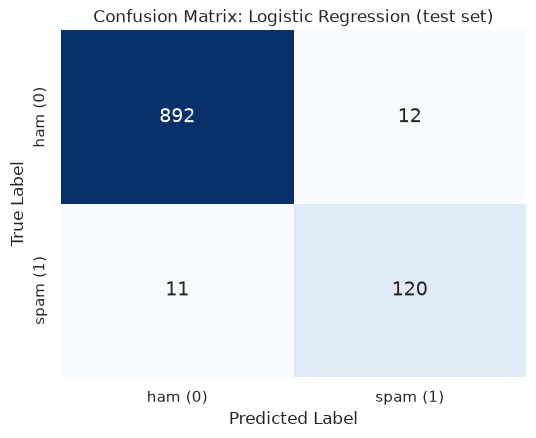

True Negatives (ham correctly kept):  892
False Positives (ham flagged as spam): 12
False Negatives (spam that got through): 11
True Positives (spam caught):          120


In [21]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, annot_kws={'size': 14},
            xticklabels=['ham (0)', 'spam (1)'], yticklabels=['ham (0)', 'spam (1)'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix: Logistic Regression (test set)')
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Negatives (ham correctly kept):  {tn}")
print(f"False Positives (ham flagged as spam): {fp}")
print(f"False Negatives (spam that got through): {fn}")
print(f"True Positives (spam caught):          {tp}")

In [22]:
# For reference: the other candidate models on the same test set
ref = []
for name, clf in candidates.items():
    p = clf.fit(X_train_vec, y_train).predict(X_test_vec)
    ref.append({'model': name, 'accuracy': accuracy_score(y_test, p),
                'spam_precision': precision_score(y_test, p), 'spam_recall': recall_score(y_test, p),
                'spam_f1': f1_score(y_test, p)})
pd.DataFrame(ref).set_index('model').round(4)

,accuracy,spam_precision,spam_recall,spam_f1
model,,,,
LogReg (default),0.9671,0.9802,0.7557,0.8534
LogReg (class_weight=balanced),0.9778,0.9091,0.9160,0.9125
Multinomial NB,0.9614,1.0000,0.6947,0.8198


### What did the model learn?

Each Logistic Regression coefficient tells us how much a feature pushes a message towards spam (positive) or ham (negative).

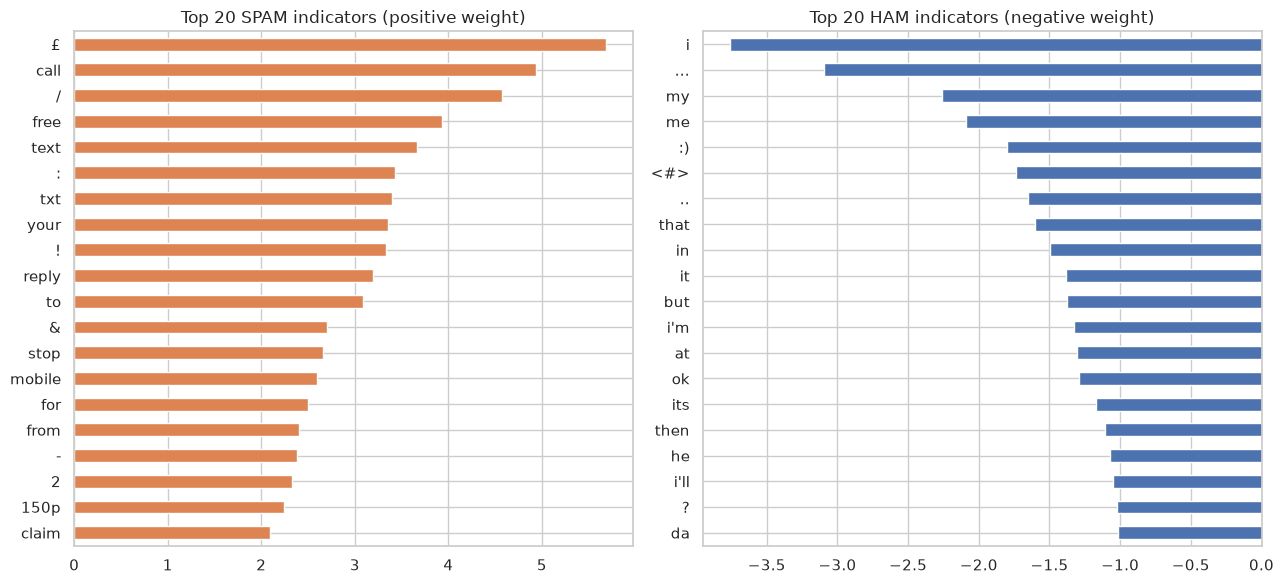

In [23]:
coefs = pd.Series(model.coef_[0], index=feature_names)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
coefs.nlargest(20).sort_values().plot.barh(ax=axes[0], color='#DD8452')
axes[0].set_title('Top 20 SPAM indicators (positive weight)')
coefs.nsmallest(20).sort_values(ascending=False).plot.barh(ax=axes[1], color='#4C72B0')
axes[1].set_title('Top 20 HAM indicators (negative weight)')
plt.tight_layout()
plt.show()

**Evaluation summary**

* On the held-out test set: **97.8% accuracy**, spam **precision 0.91, recall 0.92, F1 0.91**. The model makes 12 false positives and 11 false negatives out of 1,035 messages, so the two kinds of error are roughly balanced, as `class_weight='balanced'` intends.
* Test F1 is a little below the cross-validation estimate (0.91 vs 0.95). The test set contains only 131 spam messages, so each missed spam message changes recall by ~0.8 percentage points, and a gap of this size is within normal variance. The ranking of the three models is the same on the test set as in cross-validation.
* The strongest **spam** features are `£` (the largest weight in the model), `call`, `free`, `txt`, `text`, `reply`, `stop`, `mobile`, `claim` and `150p`, together with the symbols `/`, `:`, `!` and `&`. Every one of those symbols would have been discarded by the regex tokenizer, which confirms the tokenizer choice in Part 1. `your`, `to`, `for` and `from` are also among the top spam features; they are all on the English stop-word list, which confirms the decision to keep stop words.
* The strongest **ham** features are first-person, conversational words (`i`, `my`, `me`, `i'm`, `i'll`, `ok`), ellipses (`...`, `..`), the emoticon `:)` and the `<#>` placeholder.

---
# Part 4: Error Analysis & Reflection

## 4.1 Sample Selection

### Explanation

We collect every misclassified test message, together with the model's predicted spam probability. Errors are split into:

* **False Positives (FP)**: ham predicted as spam (a legitimate message lost).
* **False Negatives (FN)**: spam predicted as ham (spam reaching the inbox).

In [24]:
results = pd.DataFrame({'text': X_test.values, 'true': y_test.values,
                        'pred': y_pred, 'p_spam': y_proba.round(3)}, index=X_test.index)
results['n_tokens'] = results['text'].apply(lambda t: len(tweet_tokenize(t)))

false_pos = results[(results['true'] == 0) & (results['pred'] == 1)].sort_values('p_spam', ascending=False)
false_neg = results[(results['true'] == 1) & (results['pred'] == 0)].sort_values('p_spam')

print(f"False Positives: {len(false_pos)}   False Negatives: {len(false_neg)}\n")
print("=== FALSE POSITIVES (ham -> spam) ===")
display(false_pos[['text', 'p_spam', 'n_tokens']])
print("=== FALSE NEGATIVES (spam -> ham) ===")
display(false_neg[['text', 'p_spam', 'n_tokens']])

False Positives: 12   False Negatives: 11

=== FALSE POSITIVES (ham -> spam) ===


,text,p_spam,n_tokens
4416,I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS. To remove from phonebook - sms NO to &...,0.874,27
443,hanks lotsly!,0.845,3
1201,"""Hello-/@drivby-:0quit edrunk sorry iff pthis makes no senrd-dnot no how ^ dancce 2 drum n basq!ihave fun 2nhite x r...",0.740,31
3599,"Please protect yourself from e-threats. SIB never asks for sensitive information like Passwords,ATM/SMS PIN thru ema...",0.718,29
2465,Now thats going to ruin your thesis!,0.620,8
1262,Your daily text from me – a favour this time,0.606,10
2890,Your bill at 3 is £33.65 so thats not bad!,0.601,12
3522,Plz note: if anyone calling from a mobile Co. &amp; asks u to type # &lt;#&gt; or # &lt;#&gt; . Do not do so. Disco...,0.586,63
3481,"Sir, i am waiting for your call, once free please call me.",0.574,15
2199,Dont you have message offer,0.568,5


=== FALSE NEGATIVES (spam -> ham) ===


,text,p_spam,n_tokens
3743,ringtoneking 84484,0.163,2
1813,Would you like to see my XXX pics they are so hot they were nearly banned in the uk!,0.208,20
3890,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Da...",0.221,37
3949,Missed call alert. These numbers called but left no message. 07008009200,0.398,13
4499,Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo,0.414,10
5064,"Latest News! Police station toilet stolen, cops have nothing to go on!",0.450,15
1415,Bought one ringtone and now getting texts costing 3 pound offering more tones etc,0.456,14
5141,ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE MINS. INDIA CUST SERVs SED YES. L8ER GOT MEGA BILL. 3 DONT GIV A SHIT....,0.470,40
1423,Hi its LUCY Hubby at meetins all day Fri & I will B alone at hotel U fancy cumin over? Pls leave msg 2day 0909972639...,0.471,34
2180,88066 FROM 88066 LOST 3POUND HELP,0.474,6


## 4.2 Diagnostic Analysis

### Explanation

For one message, the Logistic Regression decision score is

$$\text{score} = b + \sum_j \text{tfidf}_j \times w_j$$

so the product $\text{tfidf}_j \times w_j$ is the **contribution** of each feature to the decision. The helper below prints, for a given test message:

1. the raw text, the true label, the predicted label, and $P(\text{spam})$;
2. the features **present in the message**, ranked by TF-IDF weight, with their model coefficient and contribution;
3. the features that contribute most strongly towards each class;
4. the tokens that are **out of vocabulary**: they appear in the message but the model never saw them during training (or saw them in fewer than `min_df` messages), so they are ignored.

In [25]:
LABELS = {0: 'ham', 1: 'spam'}

def diagnose(idx, top_k=10):
    text = X_test.loc[idx]
    row = X_test_vec[X_test.index.get_loc(idx)]
    dense = row.toarray()[0]
    nz = dense.nonzero()[0]

    feats = pd.DataFrame({'feature': feature_names[nz], 'tfidf': dense[nz], 'coef': coefs.values[nz]})
    feats['contribution'] = feats['tfidf'] * feats['coef']
    feats = feats.sort_values('tfidf', ascending=False).head(top_k).round(3).reset_index(drop=True)

    oov = [t for t in dict.fromkeys(tweet_tokenize(text)) if t not in vectorizer.vocabulary_]
    score = model.intercept_[0] + dense @ coefs.values

    print(f"TEXT     : {text}")
    print(f"TRUE     : {LABELS[y_test.loc[idx]]}    PREDICTED: {LABELS[int(model.predict(row)[0])]}    "
          f"P(spam) = {model.predict_proba(row)[0, 1]:.3f}")
    print(f"Decision score = intercept {model.intercept_[0]:.2f} + sum of contributions = {score:.2f}")
    print(f"Out-of-vocabulary tokens ({len(oov)}): {oov}")

    contrib = pd.Series(dense[nz] * coefs.values[nz], index=feature_names[nz]).sort_values()
    print("Strongest push towards SPAM:", contrib[contrib > 0].tail(4)[::-1].round(3).to_dict())
    print("Strongest push towards HAM: ", contrib[contrib < 0].head(4).round(3).to_dict())
    print(f"\nTop {top_k} features by TF-IDF weight:")
    display(feats)

## 4.3 Selected Failure Cases

From the errors above, we analyse three false positives and three false negatives. Each one illustrates a different weakness of the bag-of-words representation.

In [26]:
diagnose(443)   # FP

TEXT     : hanks lotsly!
TRUE     : ham    PREDICTED: spam    P(spam) = 0.845
Decision score = intercept -1.63 + sum of contributions = 1.70
Out-of-vocabulary tokens (2): ['hanks', 'lotsly']
Strongest push towards SPAM: {'!': 3.331}
Strongest push towards HAM:  {}

Top 10 features by TF-IDF weight:


,feature,tfidf,coef,contribution
0,!,1.0,3.331,3.331


### False Positive 1: very short text and out-of-vocabulary words

**Why it failed.** Both words are **out of vocabulary**: `hanks lotsly` is a playful misspelling of "thanks lots", and neither form appears in the training data. The only feature left is `!`. Every TF-IDF row is L2-normalised, so when a message has a single feature, that feature gets weight **1.0**. `!` has one of the largest spam coefficients in the model (+3.33), because spam uses exclamation marks four times as often as ham (Part 1). One punctuation mark therefore decides the prediction on its own, and the model has no other evidence that the message is a friendly reply. **Short text + OOV + normalisation** together make this kind of message very fragile. Character n-grams (`anks` is a substring of `thanks`) or spelling normalisation would give the model some real words to work with.

In [27]:
diagnose(2890)   # FP

TEXT     : Your bill at 3 is £33.65 so thats not bad!
TRUE     : ham    PREDICTED: spam    P(spam) = 0.601
Decision score = intercept -1.63 + sum of contributions = 0.41
Out-of-vocabulary tokens (1): ['33.65']
Strongest push towards SPAM: {'£': 1.368, 'your': 0.637, '!': 0.544, '3': 0.199}
Strongest push towards HAM:  {'at': -0.278, 'so': -0.206, 'not': -0.168, 'thats': -0.136}

Top 10 features by TF-IDF weight:


,feature,tfidf,coef,contribution
0,at 3,0.461,-0.042,-0.019
1,bill,0.421,0.203,0.085
2,bad,0.348,-0.112,-0.039
3,thats,0.342,-0.396,-0.136
4,3,0.299,0.664,0.199
5,£,0.240,5.688,1.368
6,at,0.213,-1.306,-0.278
7,not,0.207,-0.814,-0.168
8,so,0.207,-0.996,-0.206
9,your,0.190,3.354,0.637


### False Positive 2: a strongly weighted feature that is misleading in context

**Why it failed.** `£` is the **single strongest spam feature in the whole model** (coefficient +5.69), because 33% of spam messages contain it compared with 0.1% of ham. Here it contributes +1.37 on its own, and `your` (+0.64), `!` (+0.54) and `3` (+0.20) add to it. Together they outweigh the conversational ham cues `thats`, `so`, `at` and `not`. In context, a person is reassuring a friend about a bill, but a bag-of-words model cannot tell "*you won £1000*" from "*your bill is £33.65*". It only sees that `£` is present. The message also shows the **negation problem**: "not bad" is a positive statement, but the bigram `not bad` is too rare to survive `min_df=2`, so the model sees the unrelated unigrams `not` and `bad`. The actual amount `33.65` is out of vocabulary, as almost every specific price is.

In [28]:
diagnose(4416)   # FP

TEXT     : I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS. To remove from phonebook - sms NO to  &lt;#&gt;
TRUE     : ham    PREDICTED: spam    P(spam) = 0.874
Decision score = intercept -1.63 + sum of contributions = 1.93
Out-of-vocabulary tokens (2): ['indyarocks.com', 'phonebook']
Strongest push towards SPAM: {'free': 0.553, 'to': 0.471, 'sms': 0.455, '-': 0.356}
Strongest push towards HAM:  {'i': -0.27, '<#>': -0.243, 'u': -0.067, 'tel': -0.032}

Top 10 features by TF-IDF weight:


,feature,tfidf,coef,contribution
0,sms,0.331,1.375,0.455
1,career,0.271,0.165,0.045
2,send free,0.271,0.321,0.087
3,to <#>,0.262,-0.068,-0.018
4,added,0.255,0.131,0.033
5,sms .,0.249,0.740,0.184
6,remove,0.243,0.068,0.017
7,tel,0.239,-0.132,-0.032
8,to send,0.216,-0.083,-0.018
9,as a,0.214,0.634,0.136


### False Positive 3: ham written in a promotional register (label ambiguity)

**Why it failed.** This message is an automated notification from an SMS service ("*added u as a contact … to send FREE SMS. To remove … sms NO to …*"). Its vocabulary and structure are those of a marketing message: the strongest pushes towards spam come from `free` (+0.55), `to` (+0.47), `sms` (+0.46) and `-` (+0.36), together with the bigram `send free`, an opt-out instruction, and the `.com` domain. The few ham cues (`i`, `<#>`) are far weaker. The annotators labelled it ham, presumably because it is a service message and not an unsolicited advertisement, but the distinction depends on **who sent it and why**, which the text does not show. The model detects the *style* of spam, not intent, so it cannot separate a legitimate automated notice from a promotional one. It is also a reminder that some "errors" reflect ambiguity in the annotation itself.

In [29]:
diagnose(3743)   # FN

TEXT     : ringtoneking 84484
TRUE     : spam    PREDICTED: ham    P(spam) = 0.163
Decision score = intercept -1.63 + sum of contributions = -1.63
Out-of-vocabulary tokens (2): ['ringtoneking', '84484']
Strongest push towards SPAM: {}
Strongest push towards HAM:  {}

Top 10 features by TF-IDF weight:


,feature,tfidf,coef,contribution


### False Negative 1: every token is out of vocabulary

**Why it failed.** Both tokens, `ringtoneking` and `84484`, are **out of vocabulary**, so the TF-IDF vector is **entirely zero**. The decision score then equals the intercept (−1.63), which encodes the prior that most messages are ham, and the model outputs $P(\text{spam}) = 0.16$. This is the most extreme form of the OOV problem: the model is not misled, it simply has no input. A human recognises `ringtone` inside `ringtoneking` (the unigram `ringtone` has a spam coefficient of +1.47) and recognises `84484` as a premium short code. Two preprocessing ideas would fix this case: **character n-grams**, which would match `ringtone` inside the compound word, and **number normalisation**, which maps every 5-digit number to a shared `<SHORTCODE>` token instead of thousands of unique, rare tokens.

In [30]:
diagnose(1423)   # FN

TEXT     : Hi its LUCY Hubby at meetins all day Fri & I will B alone at hotel U fancy cumin over? Pls leave msg 2day 09099726395 Lucy x Calls£1/minMobsmoreLKPOBOX177HP51FL
TRUE     : spam    PREDICTED: ham    P(spam) = 0.471
Decision score = intercept -1.63 + sum of contributions = -0.12
Out-of-vocabulary tokens (6): ['lucy', 'hubby', 'meetins', 'cumin', '09099726395', 'minmobsmorelkpobox']
Strongest push towards SPAM: {'£': 0.668, '/': 0.552, '&': 0.328, 'msg': 0.225}
Strongest push towards HAM:  {'i': -0.232, 'at': -0.23, 'its': -0.142, 'i will': -0.098}

Top 10 features by TF-IDF weight:


,feature,tfidf,coef,contribution
0,177hp51fl,0.233,0.232,0.054
1,1 /,0.219,0.501,0.110
2,calls £,0.219,0.501,0.110
3,over ?,0.219,-0.118,-0.026
4,will b,0.219,0.288,0.063
5,& i,0.214,-0.098,-0.021
6,hi its,0.214,-0.066,-0.014
7,hotel,0.214,-0.005,-0.001
8,all day,0.209,-0.090,-0.019
9,£ 1,0.209,0.541,0.113


### False Negative 2: spam disguised as a personal message, plus tokenization noise

**Why it failed.** This spam imitates a **personal message**: it opens with "Hi its LUCY", is written in the first person (`i`, `i will`) with SMS slang (`u`, `pls`, `2day`), and ends with `x`. None of these words is spam-like, and several lean towards ham (`i`, `at`, `its`, `i will`). The spam cues are all in the last line, and that is where **tokenization** breaks down. `Calls£1/minMobsmoreLKPOBOX177HP51FL` has no spaces, so the tokenizer produces a few fragments (`£`, `1`, `/`, `177hp51fl`) and one meaningless OOV blob, `minmobsmorelkpobox`. The premium-rate number `09099726395` is OOV because every spammer uses a different number. The fragments that survive, `£` (+0.67), `/` (+0.55), `&` and `msg`, add up to about +1.5. That is just short of overcoming the intercept (−1.63, the model's prior that a message is ham), so $P(\text{spam})$ ends just below the threshold at 0.47. If the number had been recognised as a premium-rate number, it would almost certainly have tipped the decision.

In [31]:
diagnose(1813)   # FN

TEXT     : Would you like to see my XXX pics they are so hot they were nearly banned in the uk!
TRUE     : spam    PREDICTED: ham    P(spam) = 0.208
Decision score = intercept -1.63 + sum of contributions = -1.34
Out-of-vocabulary tokens (2): ['nearly', 'banned']
Strongest push towards SPAM: {'!': 0.307, 'to': 0.223, 'uk': 0.143, 'hot': 0.108}
Strongest push towards HAM:  {'my': -0.237, 'in': -0.144, 'so': -0.116, 'like': -0.074}

Top 10 features by TF-IDF weight:


,feature,tfidf,coef,contribution
0,they,0.274,-0.052,-0.014
1,they were,0.270,-0.037,-0.010
2,are so,0.270,0.370,0.100
3,xxx pics,0.270,0.228,0.061
4,see my,0.260,-0.054,-0.014
5,the uk,0.253,0.284,0.072
6,uk,0.230,0.621,0.143
7,they are,0.227,0.161,0.037
8,pics,0.222,0.358,0.079
9,like to,0.219,-0.124,-0.027


### False Negative 3: a spam sub-genre the model rarely saw

**Why it failed.** Most spam in this dataset is about **prizes, money and premium-rate services** (175 of the 522 training spam messages contain `£`). This message is adult-content spam, and it contains **none** of those cues: no `£`, no phone number, no `call` / `txt` / `claim` / `free`. The words that do carry its meaning, `xxx` (+0.35), `pics` (+0.36) and `hot` (+0.11), have only weak weights, because only 17 training spam messages contain `xxx`. `banned` is out of vocabulary. The message is phrased as a personal question ("*would you like to see **my** …*"), and `my`, one of the strongest ham features in the model (coefficient −2.26), produces the largest single push towards ham. Overall, the features add only +0.29 to the intercept, so the message is classified as ham mostly because there is **no spam evidence**, not because there is strong ham evidence. A bag-of-words model only recognises spam by the surface vocabulary it saw during training. It has no notion of the *meaning* "unsolicited sexual advertisement", so a new kind of spam passes through.

## 4.4 Overall Reflection

The error analysis shows several recurring failure patterns:

1. **The model learns style, not intent.** The strongest features are function words and punctuation (`£`, `!`, `/`, `your`, `to` for spam; `i`, `my`, `...`, `:)` for ham). That works well on average, but ham written in a promotional tone (FP 3) and spam written in a personal tone (FN 2, FN 3) are misclassified.
2. **Short messages are fragile.** With only one or two known tokens, L2 normalisation lets a single feature decide the outcome (FP 1). When there are no known tokens at all, the model falls back to the class prior (FN 1).
3. **Out-of-vocabulary tokens and variable numbers.** Phone numbers, short codes, prices and creative spellings are almost always unique, so `min_df` removes them, even though *the presence of a long number* is itself one of the strongest spam signals.
4. **No context or composition.** Bag-of-words cannot tell that "not bad" is positive or that "£" in "your bill is £33" is innocent (FP 2).
5. **Label ambiguity.** Some messages sit on the boundary between legitimate automated notifications and spam (FP 3).

**Possible improvements**, roughly from cheapest to most expensive:

* **Normalise variable tokens** before vectorising: replace phone numbers, short codes, prices and URLs with placeholder tokens (`<PHONE>`, `<SHORTCODE>`, `<PRICE>`, `<URL>`), so these strong signals survive `min_df`.
* **Character n-grams** (`TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5))`), alone or combined with word n-grams, to handle misspellings, compound words (`ringtoneking`) and glued text.
* **Hand-crafted meta-features**: message length, digit ratio, proportion of capital letters.
* **Threshold tuning**: in a real spam filter a false positive (a lost legitimate message) is usually more costly than a false negative, so the 0.5 threshold can be raised to trade some recall for precision.
* **Contextual models** (e.g., fine-tuning a small transformer such as DistilBERT), which can capture meaning and phrasing beyond the presence of individual words.

---
# Summary

| Step | Choice | Evidence |
|---|---|---|
| Data | 5,574 → **5,171** messages after removing 403 duplicates | prevents train/test leakage |
| Tokenizer | **NLTK `TweetTokenizer`** | keeps `£`, `!`, emoticons, URLs, `<#>`; best CV F1 |
| Vocabulary | `min_df=2` | 73% fewer features than `min_df=1`, with slightly higher F1 |
| Stop words | **kept** | removing them lowers CV F1 for every tokenizer |
| N-grams | `(1, 2)` | +1.6 pp F1 over unigrams; trigrams add 46% more features for no gain |
| Model | Logistic Regression, `class_weight='balanced'` | best CV F1; much higher spam recall than unweighted LR / Naive Bayes |
| **Test set** | **Accuracy 97.8% · Spam precision 0.91 · recall 0.92 · F1 0.91** | 12 FP, 11 FN out of 1,035 messages |